## 运行说明

本 notebook 是该分析的用户入口：先检查并生成所需 `logs/`，再读取结果、完成分析并把图片写入同名 `figures/` 目录。

- 默认 `FORCE_RECOMPUTE = False`：已有日志直接复用，缺失日志才计算。
- 若需要从数据重新计算本 notebook 依赖的日志，将下一单元中的开关改为 `True`。
- 耗时较长的计算保留在同目录、同主题的 `.py` 中；短计算直接写在本 notebook 中。


In [1]:
from pathlib import Path
import subprocess

PROJECT_ROOT = Path('..').resolve()
SCRIPT_DIR = PROJECT_ROOT / 'scripts'
PYTHON = PROJECT_ROOT / 'venv/bin/python'
FORCE_RECOMPUTE = False

def run_long_task(script_name, sentinel, *arguments):
    sentinel = PROJECT_ROOT / sentinel
    if FORCE_RECOMPUTE or not sentinel.exists():
        command = [str(PYTHON), str(SCRIPT_DIR / script_name), *map(str, arguments)]
        print('运行：', ' '.join(command))
        subprocess.run(command, cwd=PROJECT_ROOT, check=True)
    else:
        print('复用：', sentinel.relative_to(PROJECT_ROOT))

run_long_task('261027神经活动轨迹数据审计.py', 'logs/audit_data/initial/summary.json')


复用： logs/audit_data/initial/summary.json


### notebook 内部短计算：regional_time_arrow_bootstrap


In [2]:
from pathlib import Path
import numpy as np
import pandas as pd
from scipy.signal import detrend
from sklearn.linear_model import Ridge
from sklearn.metrics import r2_score
STATES = ('Awake', 'NREM')
ALPHAS = {('Awake', 'forward'): 100.0, ('Awake', 'reversed'): 100.0, ('NREM', 'forward'): 10.0, ('NREM', 'reversed'): 100.0}

def make_segments(labels: np.ndarray) -> pd.DataFrame:
    changes = np.r_[True, labels[1:] != labels[:-1], True]
    boundaries = np.flatnonzero(changes)
    return pd.DataFrame([{'start': int(a), 'stop': int(b), 'state': str(labels[a])} for a, b in zip(boundaries[:-1], boundaries[1:], strict=True)])

def split_state(segments: pd.DataFrame, state: str) -> tuple[pd.DataFrame, pd.DataFrame]:
    table = segments[segments.state == state].reset_index(drop=True)
    n_train = max(1, int(np.floor(0.6 * len(table))))
    n_validation = max(1, int(np.floor(0.2 * len(table))))
    return (table.iloc[:n_train], table.iloc[n_train + n_validation:])

def sample_targets(table: pd.DataFrame, rng: np.random.Generator) -> np.ndarray:
    rows = table.iloc[rng.integers(0, len(table), size=len(table))]
    return np.concatenate([np.arange(row.start + 1, row.stop, dtype=np.int64) for row in rows.itertuples(index=False) if row.stop - row.start > 1])

def episode_detrend(values: np.ndarray, segments: pd.DataFrame) -> np.ndarray:
    output = np.empty_like(values)
    for row in segments.itertuples(index=False):
        output[row.start:row.stop] = detrend(values[row.start:row.stop], axis=0, type='linear')
    return output

def reverse_episodes(values: np.ndarray, segments: pd.DataFrame) -> np.ndarray:
    output = values.copy()
    for row in segments.itertuples(index=False):
        output[row.start:row.stop] = values[row.start:row.stop][::-1]
    return output

def fit_evaluate(values: np.ndarray, train: np.ndarray, test: np.ndarray, alpha: float) -> float:
    train_frames = np.unique(np.r_[train - 1, train])
    mean, std = (values[train_frames].mean(axis=0), values[train_frames].std(axis=0))
    z = (values - mean) / np.where(std > 0, std, 1.0)
    estimator = Ridge(alpha=alpha).fit(z[train - 1], z[train] - z[train - 1])
    truth = z[test] - z[test - 1]
    prediction = estimator.predict(z[test - 1])
    return float(r2_score(truth.ravel(), prediction.ravel()))


In [3]:
from types import SimpleNamespace

regional_time_arrow_bootstrap_sentinel = PROJECT_ROOT / 'logs/regional_time_arrow_bootstrap/initial/bootstrap_summary.csv'
if FORCE_RECOMPUTE or not regional_time_arrow_bootstrap_sentinel.exists():
    args = SimpleNamespace(audit_dir=PROJECT_ROOT / 'logs/audit_data/initial', output_dir=PROJECT_ROOT / 'logs/regional_time_arrow_bootstrap/initial', replicates=200, seed=20261009)
    args.output_dir.mkdir(parents=True, exist_ok=True)
    archive = np.load(args.audit_dir / 'region_means.npz', allow_pickle=True)
    raw, labels = (archive['values'].astype(np.float64), archive['labels'].astype(str))
    segments = make_segments(labels)
    forward = episode_detrend(raw, segments)
    reversed_values = reverse_episodes(forward, segments)
    rng = np.random.default_rng(args.seed)
    rows = []
    for state in STATES:
        train_table, test_table = split_state(segments, state)
        for replicate in range(args.replicates):
            train = sample_targets(train_table, rng)
            test = sample_targets(test_table, rng)
            scores = {}
            for direction, values in (('forward', forward), ('reversed', reversed_values)):
                scores[direction] = fit_evaluate(values, train, test, ALPHAS[state, direction])
                rows.append({'state': state, 'replicate': replicate, 'direction': direction, 'dx_r2_flat': scores[direction]})
            rows.append({'state': state, 'replicate': replicate, 'direction': 'forward_minus_reversed', 'dx_r2_flat': scores['forward'] - scores['reversed']})
    result = pd.DataFrame(rows)
    result.to_csv(args.output_dir / 'bootstrap_scores.csv', index=False)
    summary = result.groupby(['state', 'direction']).dx_r2_flat.agg(median='median', q025=lambda x: x.quantile(0.025), q975=lambda x: x.quantile(0.975), positive_fraction=lambda x: np.mean(x > 0)).reset_index()
    summary.to_csv(args.output_dir / 'bootstrap_summary.csv', index=False)
    print(summary.to_string(index=False))
else:
    print('复用：', regional_time_arrow_bootstrap_sentinel.relative_to(PROJECT_ROOT))


复用： logs/regional_time_arrow_bootstrap/initial/bootstrap_summary.csv


# Episode-bootstrap test of the time arrow

Training and test episodes are resampled with replacement. Each replicate refits a full regional ridge operator to forward and episode-reversed, linearly detrended trajectories.

In [4]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from yumeow_plot import get_fig
ROOT = Path('..').resolve()
RUN = ROOT / 'logs/regional_time_arrow_bootstrap/initial'
OUT = ROOT / 'figures/261027时间箭头自助检验'
OUT.mkdir(parents=True, exist_ok=True)
scores = pd.read_csv(RUN / 'bootstrap_scores.csv')
summary = pd.read_csv(RUN / 'bootstrap_summary.csv')
summary

,state,direction,median,q025,q975,positive_fraction
0,Awake,forward,0.074053,0.017078,0.105084,0.985
1,Awake,forward_minus_reversed,-0.024842,-0.054898,-0.010106,0.000
2,Awake,reversed,0.097869,0.061553,0.126622,1.000
3,NREM,forward,0.196024,0.172435,0.219997,1.000
4,NREM,forward_minus_reversed,0.007973,-0.024024,0.034865,0.680
5,NREM,reversed,0.188485,0.152690,0.216533,1.000


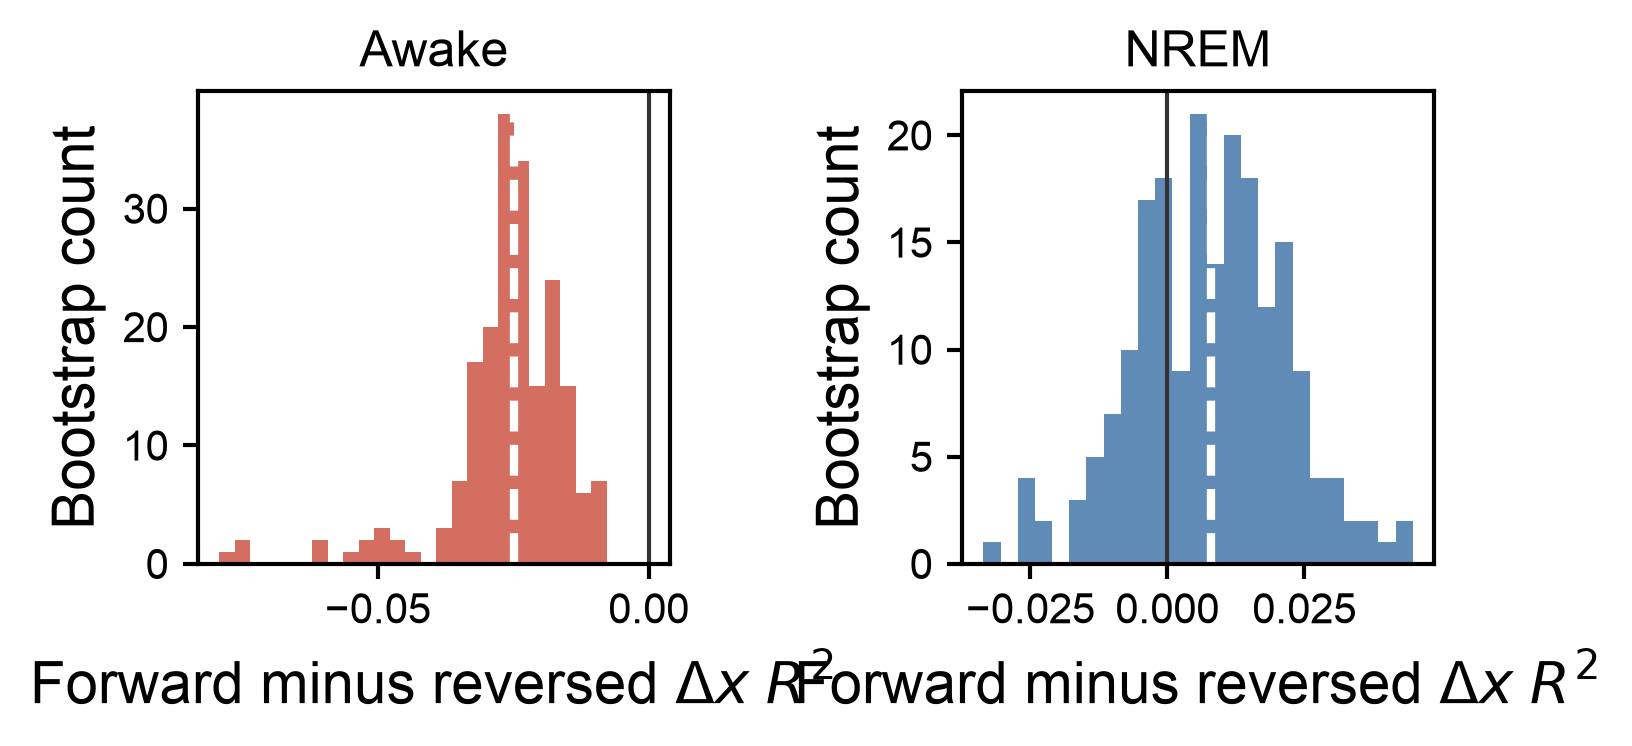

In [5]:
colors = {'Awake': '#cc5544', 'NREM': '#4477aa'}
fig, axes = get_fig(RN=1, CN=2, AW=4, AH=4, LM=5, RM=5, TM=5, BM=5, VS=5, HS=5, fontsize=14, dpi=300, lw=1)
ax_loader = iter(axes)
for state in ['Awake', 'NREM']:
    ax = next(ax_loader)
    part = scores[(scores.state == state) & (scores.direction == 'forward_minus_reversed')].dx_r2_flat
    ax.hist(part, bins=25, color=colors[state], alpha=.85)
    ax.axvline(0, color='0.2', lw=1)
    ax.axvline(part.median(), color='white', lw=2, ls='--')
    ax.set(xlabel=r'Forward minus reversed $\Delta x$ $R^2$', ylabel='Bootstrap count', title=state)
fig.savefig(OUT / 'time_arrow_bootstrap.png', transparent=True)
fig.savefig(OUT / 'time_arrow_bootstrap.svg', transparent=True)
fig.savefig(OUT / 'time_arrow_bootstrap.pdf', transparent=True)
plt.show()

Awake consistently favors reversed prediction: median forward-minus-reversed R² is -0.025 with a 95% episode-bootstrap interval [-0.055, -0.010]. NREM has a small positive median of 0.008, but its interval [-0.024, 0.035] spans zero. No state therefore provides positive, bootstrap-supported evidence that the fitted lag operator follows the physical time arrow.